# Analisis Exploratorio

## Importaciones

In [3]:
import os
import csv
import ast
import pandas as pd
import numpy as np
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
# Configurar el estilo visual de los gráficos
sns.set_theme(style="whitegrid")
palette = sns.color_palette("viridis")

## Carga de datos procesados previamente

In [7]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


In [ ]:
#USAR PARA DESCOMPRIMIR ZIP
if IN_COLAB:
    import os

    zip_drive = "/content/drive/My Drive/IIC3633/data_amazon_2018.zip"
    if not os.path.exists(zip_drive):
        zip_drive = "/content/drive/MyDrive/IIC3633/data_amazon_2018.zip"

    print(f"Buscando zip en: {zip_drive}")
    if os.path.exists(zip_drive):
        print("¡Archivo encontrado! Descomprimiendo en Colab...")
        !unzip -q "{zip_drive}" -d /content/
        print("Datos descomprimidos exitosamente.")
    else:
        print("no se encontró el archivo en esa ruta. Revisa si el nombre de la carpeta tiene mayúsculas/minúsculas.")

Buscando zip en: /content/drive/My Drive/IIC3633/data_amazon_2018.zip
¡Archivo encontrado! Descomprimiendo en Colab...
replace /content/data_amazon_2018/info/Musical_Instruments_5_2015-1-2018-11.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/__pycache__/process.cpython-312.pyc? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/info/Video_Games.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/process.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/test/Toys_and_Games_5_2017-1-2018-11.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/test/CDs_and_Vinyl_5_2015-10-2018-11.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/valid/Video_Games_5_2015-4-2018-11.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data_amazon_2018/test/Musical_Instruments_5_2015-1-2018-11.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [8]:
base = 'data_amazon_2018' if IN_COLAB else os.path.join('..', 'repo_latentr3', 'data')
names = {"CDs_and_Vinyl": "cd_data",
         "Musical_Instruments": "music_data",
         "Toys_and_Games": "toys_data",
         "Video_Games": "games_data"}
list_cols = ["item_asins", "history_item_id", "history_item_title", "history_rating", "history_timestamp"]

def get_name(nombre_archivo):
    for categoria, nombre in names.items():
        if nombre_archivo.startswith(categoria):
            return nombre

def add_data_csv(dir, data_dict):
    for nombre_archivo in os.listdir(dir):
        df = pd.read_csv(os.path.join(dir, nombre_archivo))
        for col in list_cols:
            df[col] = df[col].apply(ast.literal_eval)
        data_dict[get_name(nombre_archivo)] = df

def add_data_info(dir, data_dict):
    for nombre_archivo in os.listdir(dir):
        filas = []
        with open(os.path.join(dir, nombre_archivo), encoding="utf-8") as f:
            for linea in f:
                title, item_id = linea.rstrip("\n").rsplit("\t", 1)
                filas.append((title, int(item_id)))
        data_dict[get_name(nombre_archivo)] = pd.DataFrame(filas, columns=["title", "item_id"])

In [9]:
info, train, valid, test = {}, {}, {}, {}
add_data_info(os.path.join(base, "info"), info)
add_data_csv(os.path.join(base, "train"), train)
add_data_csv(os.path.join(base, "valid"), valid)
add_data_csv(os.path.join(base, "test"), test)

### Analisis de los Datos

#### Primeras filas de los DataFrames cargados

In [10]:
print("Categorías disponibles:", list(train.keys()))

ejemplo_cat = 'games_data'

print(f"\n--- Información de ítems (info) para {ejemplo_cat} ---")
display(info[ejemplo_cat].head())

print(f"\n--- Datos de Entrenamiento (train) para {ejemplo_cat} ---")
display(train[ejemplo_cat].head(2))

print(f"\n--- Datos de Validación (valid) para {ejemplo_cat} ---")
display(valid[ejemplo_cat].head(2))

print(f"\n--- Datos de Prueba (test) para {ejemplo_cat} ---")
display(test[ejemplo_cat].head(2))

Categorías disponibles: ['cd_data', 'music_data', 'games_data', 'toys_data']

--- Información de ítems (info) para games_data ---


,title,item_id
0,Max Payne 2: The Fall of Max Payne - PlayStati...,0
1,Spartan: Total Warrior - PlayStation 2,1
2,DISNEY INFINITY Starter Pack Xbox 360,2
3,Need for Speed: Rivals,3
4,GGG0032 2 pack Extension Cable for Wii Classic...,4



--- Datos de Entrenamiento (train) para games_data ---


,user_id,item_asins,item_asin,history_item_id,item_id,history_item_title,item_title,history_rating,rating,history_timestamp,timestamp
0,A34FNHVP8TJNWD,[B00004YRQA],B00006F2ZP,[3776],3563,[PlayStation 2 Memory Card (8MB)],Spyro: Enter the Dragonfly,[5.0],5.0,[1427846400],1427846400
1,A34FNHVP8TJNWD,"[B00004YRQA, B00006F2ZP]",B000TLU67W,"[3776, 3563]",2746,"[PlayStation 2 Memory Card (8MB), Spyro: Enter...",PlayStation 2 Console Slim PS2,"[5.0, 5.0]",5.0,"[1427846400, 1427846400]",1427846400



--- Datos de Validación (valid) para games_data ---


,user_id,item_asins,item_asin,history_item_id,item_id,history_item_title,item_title,history_rating,rating,history_timestamp,timestamp
0,A3PMELM6ZYZU94,"[B00005O0I2, B0000696CZ, B0009R1T9K, B00J48MUS...",B00QU47SJG,"[476, 2666, 2248, 4172, 3562, 331]",4246,"[Grand Theft Auto III, Grand Theft Auto Vice C...",Final Fantasy X X-2 HD Remaster Standard Editi...,"[5.0, 5.0, 5.0, 5.0, 5.0, 5.0]",5.0,"[1490832000, 1490832000, 1490832000, 149083200...",1490832000
1,A3PMELM6ZYZU94,"[B00005O0I2, B0000696CZ, B0009R1T9K, B00J48MUS...",B000056SNY,"[476, 2666, 2248, 4172, 3562, 331, 4246]",4679,"[Grand Theft Auto III, Grand Theft Auto Vice C...",The Bouncer,"[5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0]",5.0,"[1490832000, 1490832000, 1490832000, 149083200...",1490832000



--- Datos de Prueba (test) para games_data ---


,user_id,item_asins,item_asin,history_item_id,item_id,history_item_title,item_title,history_rating,rating,history_timestamp,timestamp
0,A2I7GFSJQ34ATV,"[B00L4KVFV8, B002AB7TX8, B0053BQJVA, B006PP41Q...",B01GKHJPG6,"[621, 2369, 2187, 886, 3930, 3471, 5075, 3675,...",2296,[PlayStation All-Stars Battle Royale PS Vita -...,Persona 5 - SteelBook Edition - PlayStation 4,"[3.0, 5.0, 1.0, 5.0, 3.0, 3.0, 3.0, 5.0, 3.0, ...",5.0,"[1427846400, 1428019200, 1428019200, 142801920...",1506211200
1,A3SF7H6PLINYGN,"[B004K1EA5G, B0029MAXR2]",B017S3OPZM,"[1193, 559]",4077,"[Dead or Alive Dimensions, Ninja Gaiden Sigma ...",NieR: Automata - Playstation 4,"[5.0, 5.0]",5.0,"[1481155200, 1484179200]",1506211200


#### Tablas de estadisticas (Sparsity y tamaño)

In [11]:
def generate_stats_table(train_dict, valid_dict):
    stats = []

    for split_name, split_dict in [("Entrenamiento", train_dict), ("Validación", valid_dict)]:
        for name, df in split_dict.items():

            target_pairs = df[['user_id', 'item_id']].copy()
            hist_df = df[['user_id', 'history_item_id']].explode('history_item_id')
            hist_df = hist_df.rename(columns={'history_item_id': 'item_id'})
            all_pairs = pd.concat([target_pairs, hist_df]).dropna().drop_duplicates()

            unique_users = all_pairs['user_id'].nunique()
            num_unique_items = all_pairs['item_id'].nunique()
            num_interactions = len(all_pairs)
            if unique_users * num_unique_items > 0:
                sparsity = 1.0 - (num_interactions / (unique_users * num_unique_items))
            else:
                sparsity = 0

            stats.append({
                "Split": split_name,
                "Dataset": name,
                "Usuarios Únicos": f"{unique_users:,}",
                "Ítems Únicos (en split)": f"{num_unique_items:,}",
                "Interacciones Reales": f"{num_interactions:,}",
                "Largo Prom. Historial": round(num_interactions / unique_users, 2) if unique_users > 0 else 0,
                "Sparsity": f"{(sparsity * 100):.4f}%"
            })

    return pd.DataFrame(stats)

df_stats = generate_stats_table(train, valid)
display(df_stats)

,Split,Dataset,Usuarios Únicos,Ítems Únicos (en split),Interacciones Reales,Largo Prom. Historial,Sparsity
0,Entrenamiento,cd_data,"6,865","5,837","54,778",7.98,99.8633%
1,Entrenamiento,music_data,"10,899","5,010","73,302",6.73,99.8658%
2,Entrenamiento,games_data,"12,119","5,251","85,036",7.02,99.8664%
3,Entrenamiento,toys_data,"10,167","6,269","61,326",6.03,99.9038%
4,Validación,cd_data,"1,907","4,987","15,222",7.98,99.8399%
5,Validación,music_data,"3,082","4,520","22,000",7.14,99.8421%
6,Validación,games_data,"3,255","4,574","23,469",7.21,99.8424%
7,Validación,toys_data,"2,455","5,136","15,586",6.35,99.8764%


#### Gráfico de Popularidad de Ítems

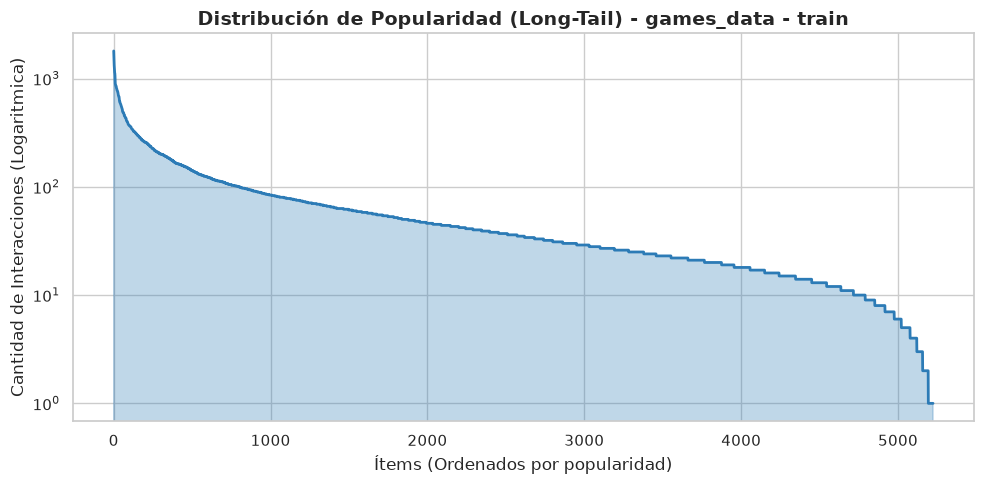

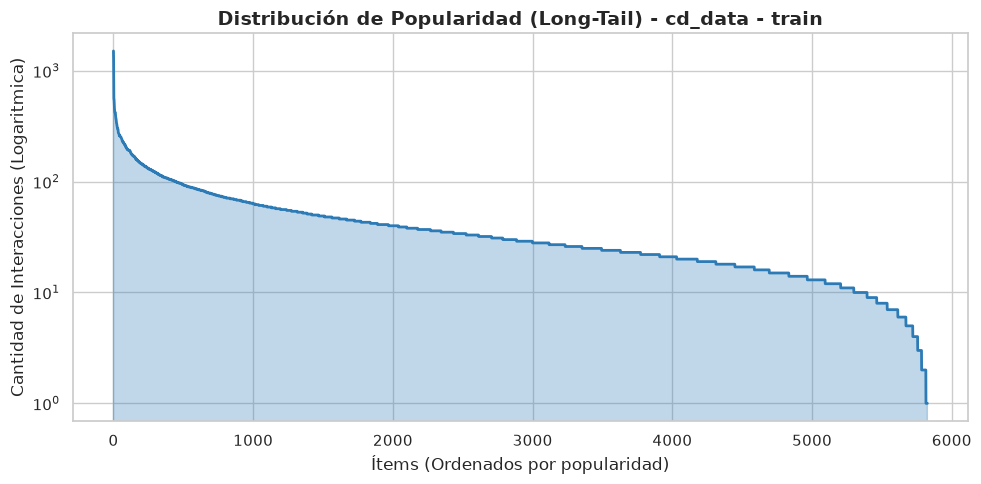

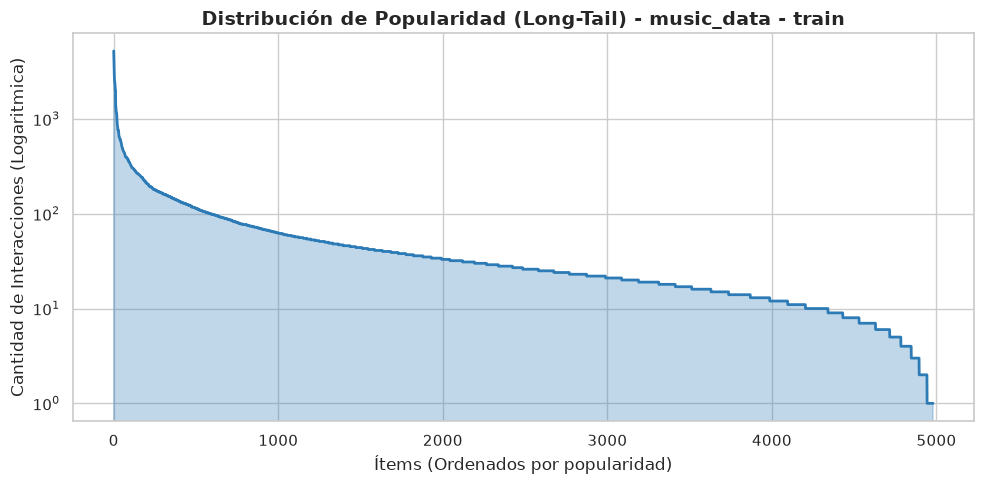

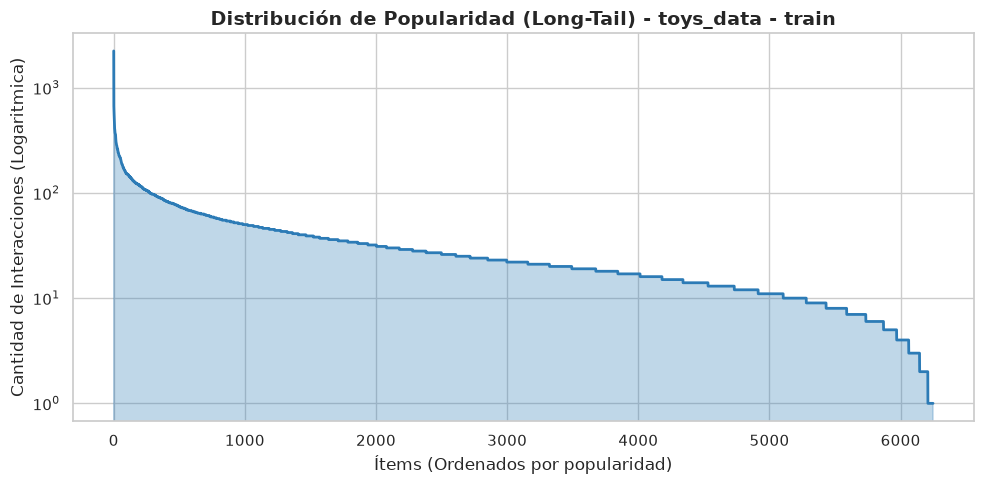

In [12]:
def plot_long_tail(df_dict,type_dict, dataset_name):
    df = df_dict[dataset_name]
    all_items = [item for sublist in df['history_item_id'] for item in sublist]

    item_counts = pd.Series(all_items).value_counts().values

    plt.figure(figsize=(10, 5))
    plt.plot(item_counts, color='#2c7bb6', linewidth=2)
    plt.fill_between(range(len(item_counts)), item_counts, color='#2c7bb6', alpha=0.3)

    plt.title(f"Distribución de Popularidad (Long-Tail) - {dataset_name} - {type_dict}", fontsize=14, weight='bold')
    plt.xlabel("Ítems (Ordenados por popularidad)", fontsize=12)
    plt.ylabel("Cantidad de Interacciones (Logaritmica)", fontsize=12)
    plt.yscale('log')
    plt.tight_layout()
    plt.show()

plot_long_tail(train, "train","games_data")
plot_long_tail(train, "train","cd_data")
plot_long_tail(train, "train","music_data")
plot_long_tail(train, "train","toys_data")

#### Longitud de historial previo de usuario

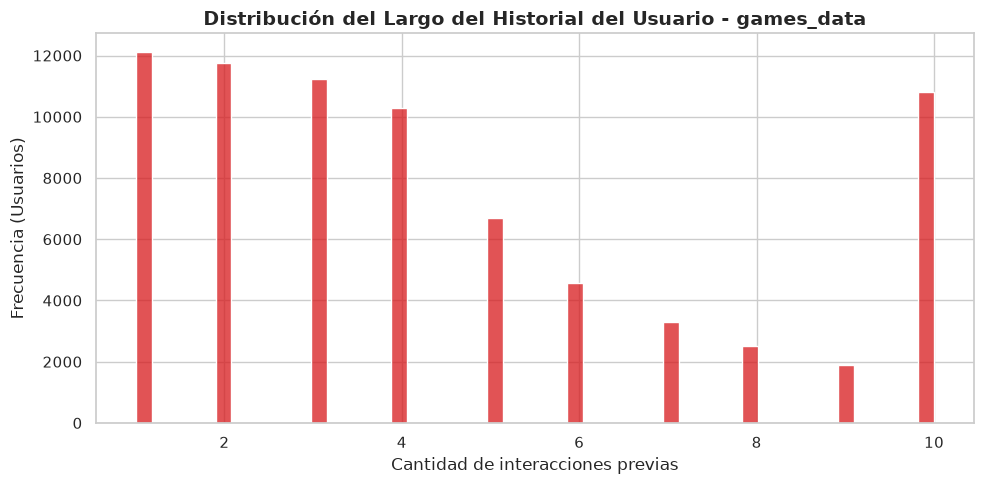

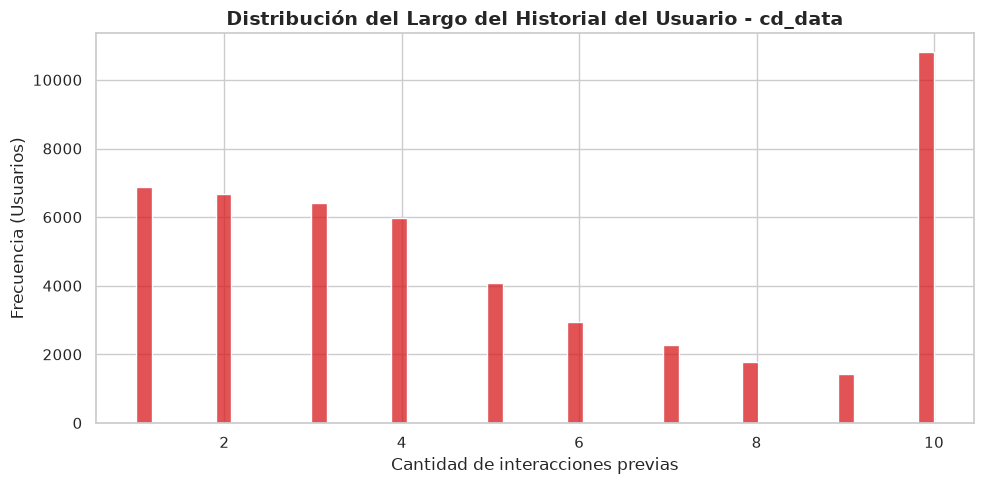

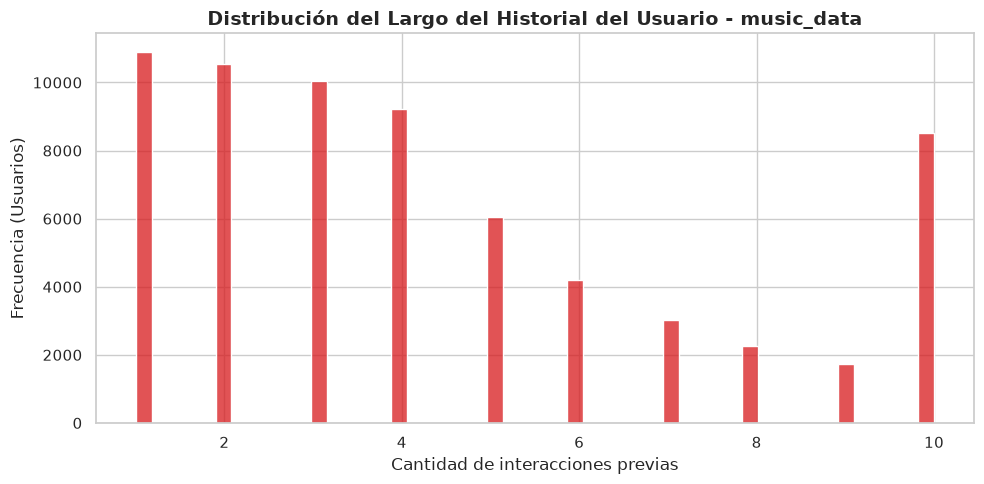

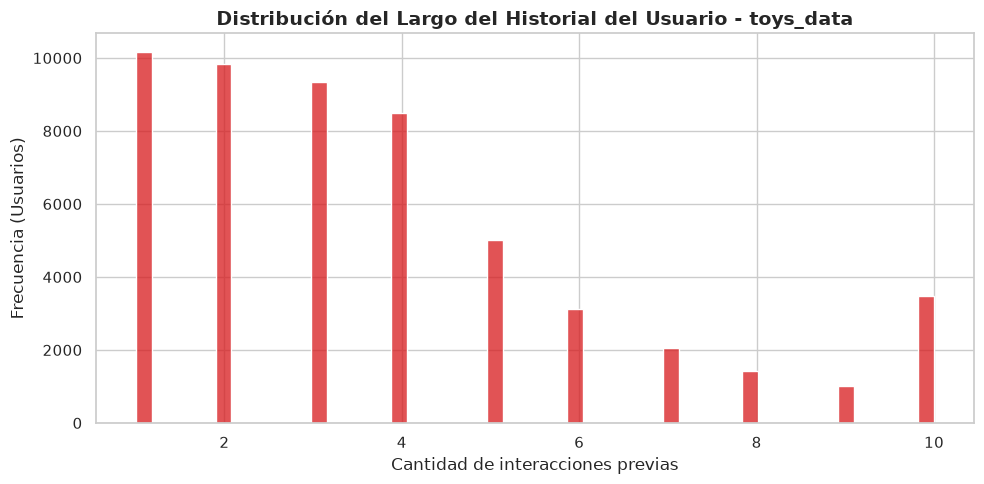

In [13]:
def plot_sequence_lengths(df_dict, dataset_name):
    df = df_dict[dataset_name]
    seq_lengths = df['history_item_id'].apply(len)

    plt.figure(figsize=(10, 5))
    sns.histplot(seq_lengths, bins=50, kde=False, color='#d7191c')

    plt.title(f"Distribución del Largo del Historial del Usuario - {dataset_name}", fontsize=14, weight='bold')
    plt.xlabel("Cantidad de interacciones previas", fontsize=12)
    plt.ylabel("Frecuencia (Usuarios)", fontsize=12)
    plt.tight_layout()
    plt.show()

plot_sequence_lengths(train, "games_data")
plot_sequence_lengths(train, "cd_data")
plot_sequence_lengths(train, "music_data")
plot_sequence_lengths(train, "toys_data")

#### Distribucion de Ratings

In [14]:
def generate_ratings_table(df_dict):
    ratings_data = []
    for name, df in df_dict.items():
        all_ratings = [rating for sublist in df['history_rating'] for rating in sublist]
        counts = pd.Series(all_ratings).value_counts(normalize=True) * 100

        row = {"Dataset": name}
        for star in [1.0, 2.0, 3.0, 4.0, 5.0]:
            row[f"{int(star)} Estrellas (%)"] = f"{counts.get(star, 0.0):.2f}%"

        ratings_data.append(row)

    return pd.DataFrame(ratings_data)

df_ratings_dist = generate_ratings_table(train)
display(df_ratings_dist)

,Dataset,1 Estrellas (%),2 Estrellas (%),3 Estrellas (%),4 Estrellas (%),5 Estrellas (%)
0,cd_data,0.94%,1.30%,4.37%,13.28%,80.10%
1,music_data,2.43%,2.73%,6.32%,15.75%,72.77%
2,games_data,4.87%,3.07%,7.20%,14.47%,70.38%
3,toys_data,1.74%,2.09%,5.76%,14.14%,76.27%


#### Proporcion de Cold-Start (<= 5)

In [15]:
def calculate_cold_start_ratio(train_dict, info_dict, threshold=5):
    metrics = []
    for name, df in train_dict.items():
        all_items = [item for sublist in df['history_item_id'] for item in sublist]
        item_counts = pd.Series(all_items).value_counts()
        cold_start_items = (item_counts <= threshold).sum()
        total_unique_items = info_dict[name].shape[0] if name in info_dict else len(set(all_items))
        cold_start_ratio = cold_start_items / total_unique_items

        metrics.append({
            "Dataset": name,
            f"Ítems Cold-Start (<={threshold})": f"{cold_start_items:,}",
            f"% Cold-Start": f"{cold_start_ratio:.2%}"
        })

    return pd.DataFrame(metrics)

df_cold_start = calculate_cold_start_ratio(train, info, threshold=5)
display(df_cold_start)

,Dataset,Ítems Cold-Start (<=5),% Cold-Start
0,cd_data,154,2.64%
1,music_data,264,5.25%
2,games_data,203,3.82%
3,toys_data,378,6.00%


#### Diferencia de tiempo entre compras en historial

In [16]:
def calculate_time_gaps(train_dict):
    metrics = []
    for name, df in train_dict.items():
        all_time_gaps = []
        for timestamps in df['history_timestamp']:
            if len(timestamps) > 1:
                sorted_ts = sorted(timestamps)
                gaps = np.diff(sorted_ts) / (60 * 60 * 24)
                all_time_gaps.extend(gaps)
        median_gap = np.median(all_time_gaps) if all_time_gaps else 0
        mean_gap = np.mean(all_time_gaps) if all_time_gaps else 0

        metrics.append({
            "Dataset": name,
            "Brecha Mediana (Días)": f"{median_gap:.1f}",
            "Brecha Promedio (Días)": f"{mean_gap:.1f}"
        })

    return pd.DataFrame(metrics)

# Ejecutar y mostrar
df_time_gaps = calculate_time_gaps(train)
display(df_time_gaps)

,Dataset,Brecha Mediana (Días),Brecha Promedio (Días)
0,cd_data,0.0,19.5
1,music_data,0.0,33.1
2,games_data,0.0,23.8
3,toys_data,0.0,15.0


## Métricas

In [17]:
def hit(recs, objetivo, k):
    return 1 if objetivo in list(recs[:k]) else 0

def ndcg(recs, objetivo, k):
    recs = list(recs[:k])
    if objetivo not in recs:
        return 0
    pos = recs.index(objetivo)
    return 1 / np.log2(pos + 2)

In [18]:
def evaluar(recomendaciones, test_df, ks=[5, 10]):
    resultados = {}
    for k in ks:
        resultados[f"HR@{k}"] = np.mean([hit(r, o, k) for r, o in zip(recomendaciones, test_df["item_id"])])
        resultados[f"NDCG@{k}"] = np.mean([ndcg(r, o, k) for r, o in zip(recomendaciones, test_df["item_id"])])
    return resultados

## Random

In [19]:
def random_recommender(items, n_usuarios, k=10, seed=42):
    rng = np.random.default_rng(seed)
    return [rng.choice(items, size=k, replace=False) for _ in range(n_usuarios)]

## Most Popular

In [20]:
def most_popular_recommender(train_df, n_usuarios, k=10):
    top = train_df["item_id"].value_counts().index[:k].tolist()
    return [top] * n_usuarios

# Last Item (Secuencial)

In [21]:
def last_item_recommender(test_df, train_df, k=10):
    top_pop = train_df["item_id"].value_counts().index[:k].tolist()
    def rec_usuario(hist):
        recientes = list(dict.fromkeys(reversed(hist)))
        return (recientes + [x for x in top_pop if x not in recientes])[:k]
    return [rec_usuario(hist) for hist in test_df["history_item_id"]]

# Evaluar los 3 Modelos

In [22]:
from IPython.display import HTML
filas = []
for nombre in names.values():
    items = info[nombre]["item_id"].values
    n = len(test[nombre])
    filas.append({"dataset": nombre, "modelo": "Random",
                  **evaluar(random_recommender(items, n), test[nombre])})
    filas.append({"dataset": nombre, "modelo": "MostPop",
                  **evaluar(most_popular_recommender(train[nombre], n), test[nombre])})
    filas.append({"dataset": nombre, "modelo": "LastItem (Secuencial)",
                  **evaluar(last_item_recommender(test[nombre], train[nombre]), test[nombre])})
resultados = pd.DataFrame(filas).round(4)
resultados = resultados.reset_index().rename(columns={"index": "#"})
resultados
HTML(resultados.to_html(index=False))



#,dataset,modelo,HR@5,NDCG@5,HR@10,NDCG@10
0,cd_data,Random,0.0008,0.0004,0.0018,0.0007
1,cd_data,MostPop,0.0130,0.0081,0.0192,0.0101
2,cd_data,LastItem (Secuencial),0.0119,0.0110,0.0151,0.0120
3,music_data,Random,0.0017,0.0009,0.0026,0.0012
4,music_data,MostPop,0.0410,0.0268,0.0659,0.0348
5,music_data,LastItem (Secuencial),0.0289,0.0160,0.0544,0.0242
6,toys_data,Random,0.0012,0.0006,0.0021,0.0008
7,toys_data,MostPop,0.0098,0.0071,0.0137,0.0083
8,toys_data,LastItem (Secuencial),0.0150,0.0135,0.0197,0.0150
9,games_data,Random,0.0009,0.0006,0.0021,0.0011
